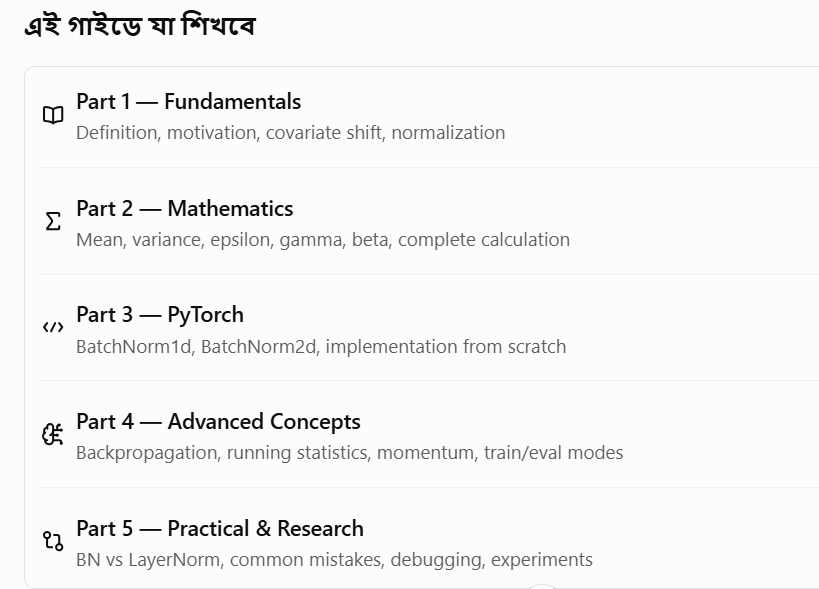

#Batch Normalization কী? (Deep Learning)
Batch Normalization (BN) হলো Deep Learning-এর একটি technique, যা Neural Network-এর training-কে আরও stable এবং অনেক ক্ষেত্রে faster করতে সাহায্য করে।

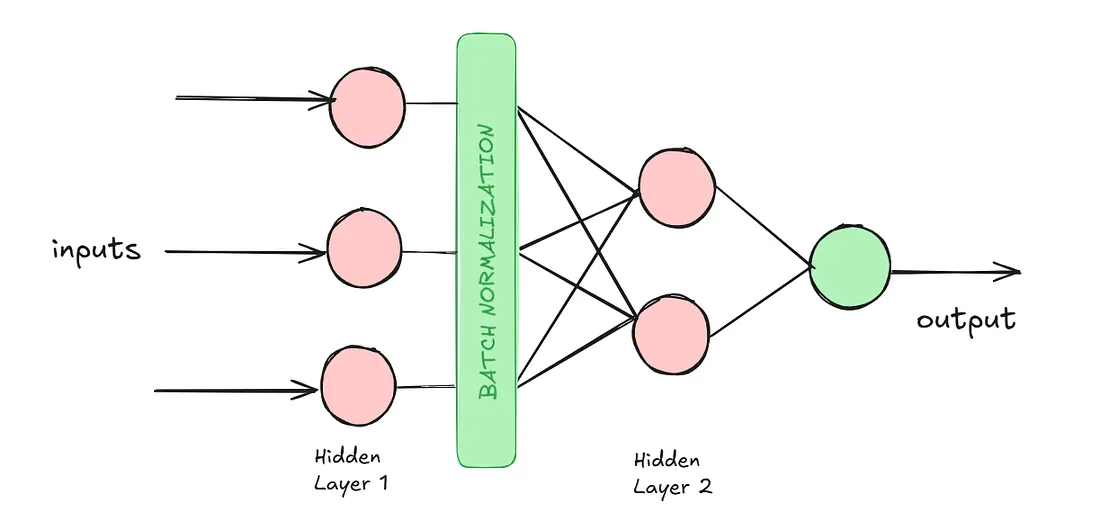

#1. কেন Batch Normalization ব্যবহার করা হয়?

ধরো, তুমি একটি Neural Network train করছ। Training-এর সময় প্রতিটি layer-এর output বা activation-এর মান অনেক পরিবর্তিত হতে পারে। এর ফলে পরবর্তী layer-এর training কঠিন হতে পারে।
Batch Normalization এই activation-গুলোকে একটি নিয়ন্ত্রিত scale-এ নিয়ে আসে।

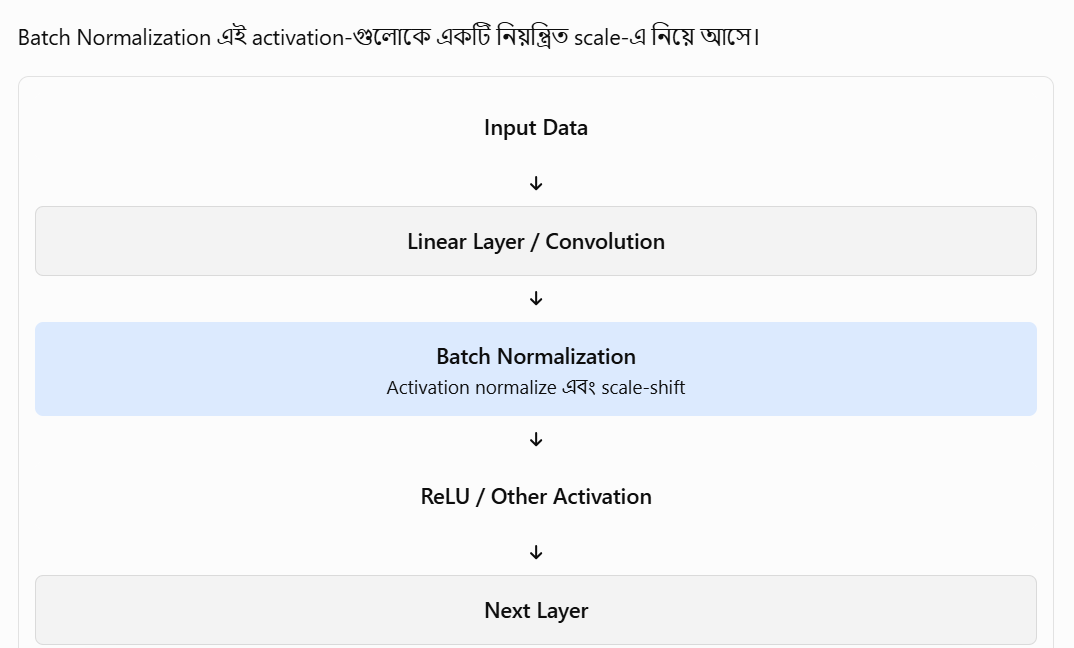

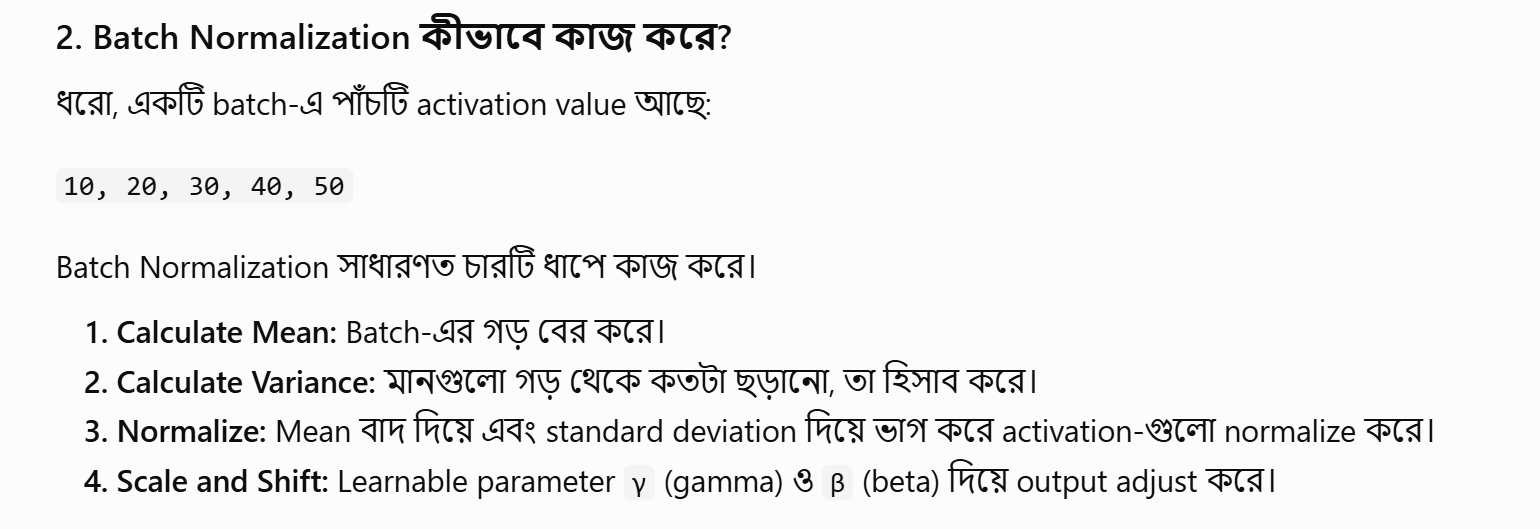

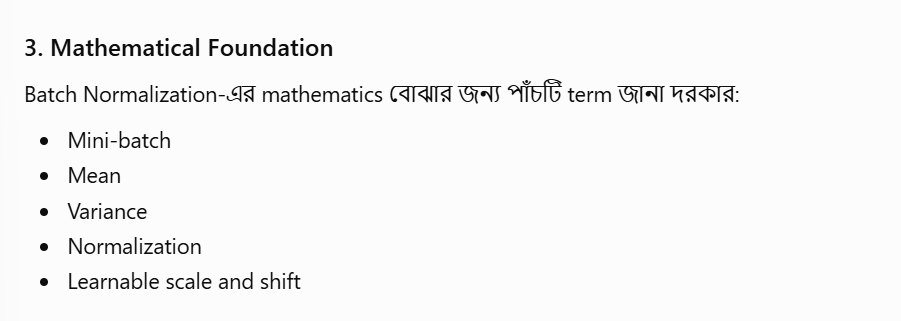

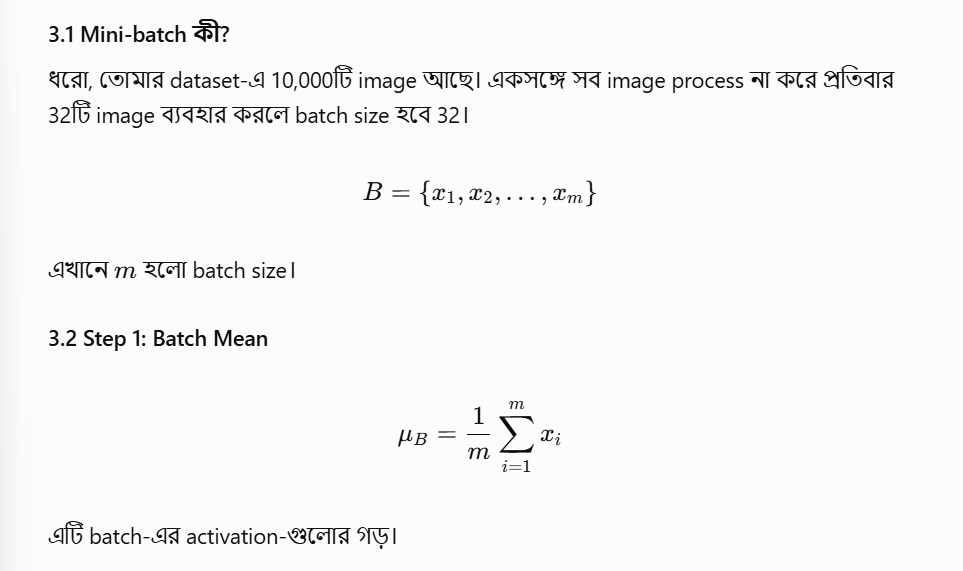

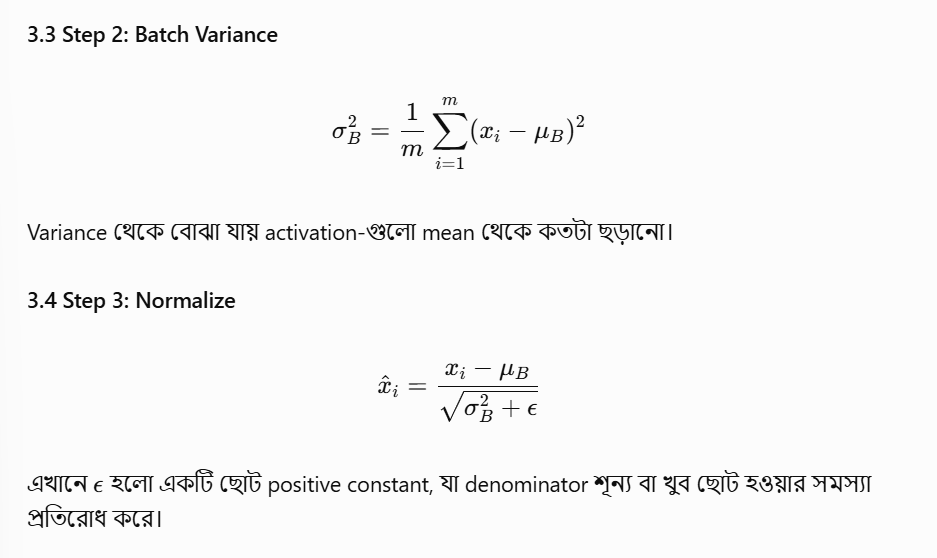

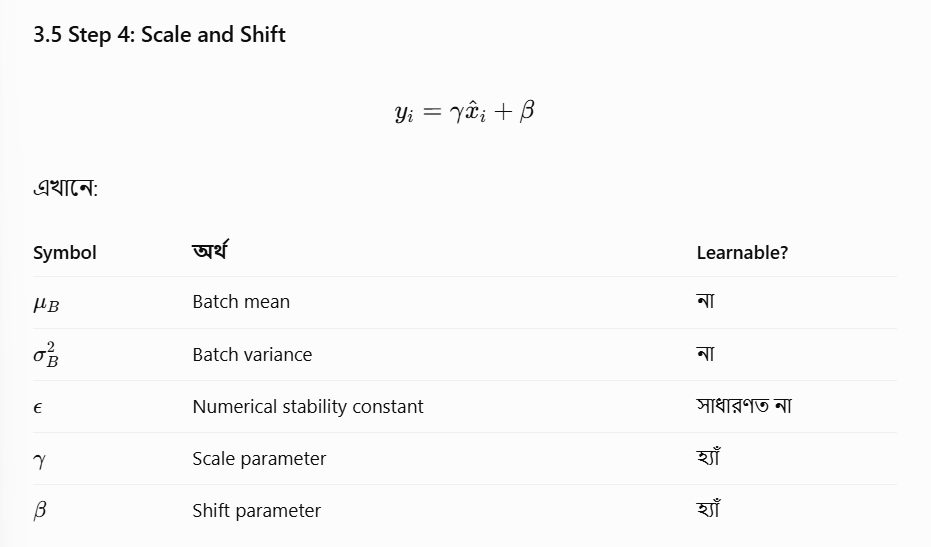

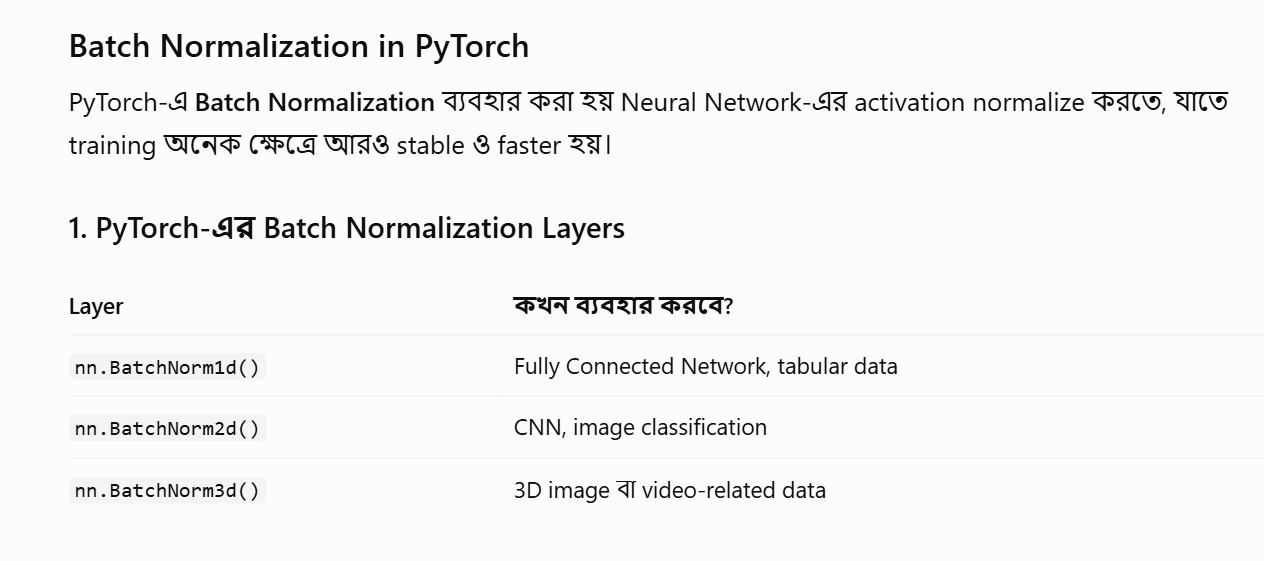

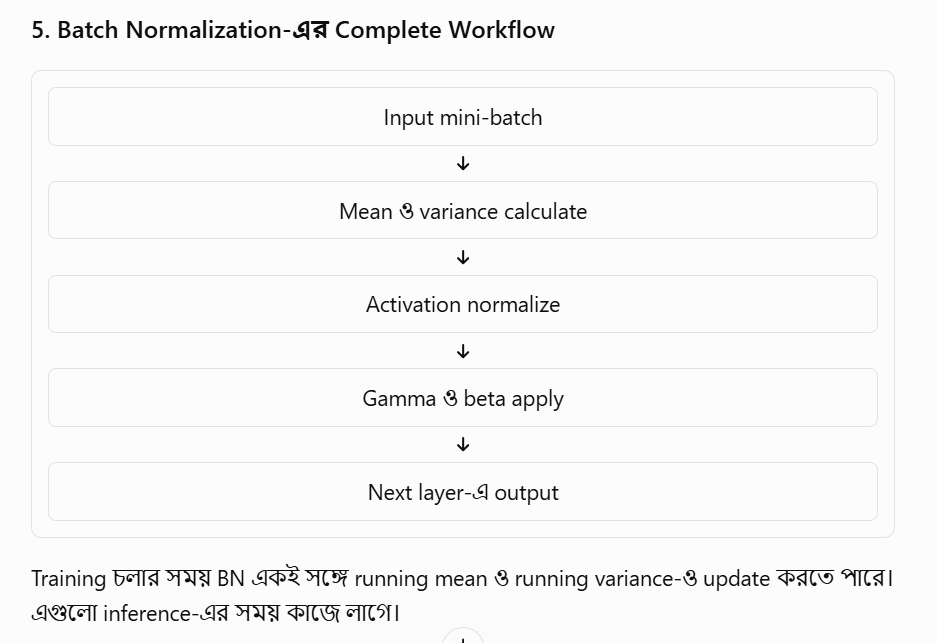

In [ ]:
import torch
import torch.nn as nn

x=torch.tensor([
    [1.0,10.0,100.0],
    [2.0,20.0,200.0],
    [3.0,30.0,300.0],
    [4.0,40.0,400.0]
])
bn=nn.BatchNorm1d(3)
output=bn(x)
print("Original Input:\n", x)
print("Normalized Output:\n", output)

Original Input:
 tensor([[  1.,  10., 100.],
        [  2.,  20., 200.],
        [  3.,  30., 300.],
        [  4.,  40., 400.]])
Normalized Output:
 tensor([[-1.3416, -1.3416, -1.3416],
        [-0.4472, -0.4472, -0.4472],
        [ 0.4472,  0.4472,  0.4472],
        [ 1.3416,  1.3416,  1.3416]], grad_fn=<NativeBatchNormBackward0>)


Training mode-এ default initialization থাকলে output-এর প্রতিটি feature-এর batch mean প্রায় 0 এবং variance প্রায় 1 হবে।

In [ ]:
#2d normal form
import torch
import torch.nn as nn

bn=nn.BatchNorm2d(num_features=32)

x=torch.randn(8,32,64,64)
output=bn(x)
print(output.shape)

torch.Size([8, 32, 64, 64])


In [ ]:
#BatchNorm3d
bn = nn.BatchNorm3d(16)

x = torch.randn(4, 16, 8, 32, 32)

output = bn(x)


#7. Batch Normalization from Scratch

In [ ]:
import torch

def batch_norm_manual(x, eps=1e-5):
    mean = x.mean(dim=0)
    var = x.var(dim=0, unbiased=False)

    x_normalized = (x - mean) / torch.sqrt(var + eps)

    return x_normalized

x = torch.tensor([
    [2.0, 10.0],
    [4.0, 20.0],
    [6.0, 30.0],
    [8.0, 40.0]
])

output = batch_norm_manual(x)

print(output)

tensor([[-1.3416, -1.3416],
        [-0.4472, -0.4472],
        [ 0.4472,  0.4472],
        [ 1.3416,  1.3416]])


#3. Neural Network-এ Batch Normalization


একটি সাধারণ Fully Connected Neural Network দেখি।

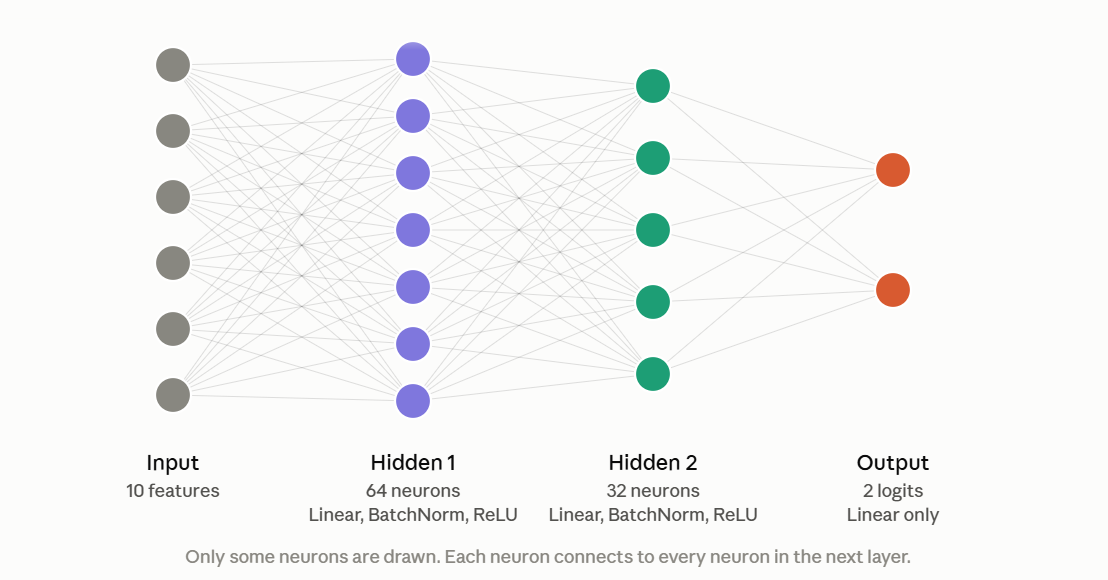

In [ ]:
import torch
import torch.nn as nn

class NeuralNetwork(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(10, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),

            nn.Linear(64, 32),
            nn.BatchNorm1d(32),
            nn.ReLU(),

            nn.Linear(32, 16),
            nn.BatchNorm1d(16),
            nn.ReLU(),
        )

    def forward(self, x):
        return self.network(x)

4. Training-এর সময় Batch Normalization

In [ ]:
from torch.utils.data import TensorDataset, DataLoader

# new model
model = NeuralNetwork()

x_dummy = torch.randn(100, 10)
y_dummy = torch.randn(100, 16)
dataset = TensorDataset(x_dummy, y_dummy)
train_loader = DataLoader(dataset, batch_size=16, shuffle=True)

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)


print("Model ,dataloader, Loss function and optimizer are create succesfully")

Model ,dataloader, Loss function and optimizer are create succesfully


#4. Training Time Batch Normalization

In [ ]:
model.train()
for x,y in train_loader:
    optimizer.zero_grad()

    predictions=model(x)
    loss=criterion(predictions,y)

    loss.backward()
    optimizer.step()

#5. Testing time

In [ ]:
import torch

test_data = torch.randn(5, 10)

model.eval()
with torch.no_grad():
    predictions = model(test_data)

print("Predictions:\n", predictions)

Predictions:
 tensor([[0.0000, 0.4427, 0.0000, 0.0000, 0.0000, 0.0000, 0.0726, 0.0000, 0.0000,
         0.0000, 0.1058, 0.1976, 0.0000, 0.1338, 0.1951, 0.2574],
        [0.0000, 0.0000, 0.0000, 0.0000, 0.0579, 0.0000, 0.0223, 0.0000, 0.0000,
         0.0519, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0641],
        [0.0000, 0.0000, 0.0476, 0.0965, 0.0000, 0.0000, 0.1938, 0.0000, 0.0000,
         0.1023, 0.3814, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.0000, 0.0000, 0.0000, 0.1445, 0.0660, 0.0000, 0.4720, 0.0000, 0.0000,
         0.0000, 0.1299, 0.0000, 0.0000, 0.0000, 0.3957, 0.0000],
        [0.1652, 0.0000, 0.2994, 0.0628, 0.1307, 0.0532, 0.0000, 0.0852, 0.0000,
         0.0647, 0.1309, 0.2353, 0.0202, 0.0000, 0.0000, 0.0000]])
